# 00-1　觀看前須知：讀懂 01 需要的物理與數學

**給誰看**：物理學到高中程度、會寫 Python 的人。
**目標**：讀完這本，再回去看 [01_orbits](../01_newton/01_orbits.ipynb)，每一段都看得懂。

每個主題都照同一個順序講：

> **白話** → **公式** → **跑程式親手看** → **01 哪裡會用到**

不需要會微積分。會用到微積分的地方，都改用「切成很小的一步」來理解，這其實也正是電腦做模擬的方法。

| 章節 | 內容 | 01 對應的地方 |
|---|---|---|
| 0 | 符號對照表 | 全部 |
| 1 | 向量：有方向的量 | `r`、`v` 都是向量 |
| 2 | 速度和加速度：「變化率」 | 公式裡的 $\dot r$、$\ddot r$ |
| 3 | 一小步一小步：電腦怎麼算運動 | 實驗 1 的積分器 |
| 4 | 萬有引力和行星軌道 | `kepler_acc`、$GM = 4\pi^2$ |
| 5 | 能量守恆：抓出模擬誤差 | 實驗 1 的能量圖 |
| 6 | 橢圓和克卜勒三定律 | 實驗 2 |
| 7 | 進動：會轉的橢圓 | 實驗 3、4 |
| 8 | 角秒：43″ 到底有多小 | 實驗 4 的結論 |
| 9 | 誤差「正比於 $dt^2$」是什麼意思 | 實驗 3 的表格 |

## 0. 符號對照表

物理書裡最嚇人的常常不是觀念，而是符號。先把 01 會出現的都列出來：

| 符號 | 念法 | 意思 |
|---|---|---|
| $\vec r$ | r 向量 | 位置（從太陽指向行星的箭頭） |
| $r$ 或 $\lvert\vec r\rvert$ | r | 位置向量的**長度**，也就是距離 |
| $\vec v$ | v 向量 | 速度 |
| $\dot r$ | r dot | r 對時間的變化率，也就是速度。**上面一點 = 對時間變化一次** |
| $\ddot r$ | r double dot | 變化率的變化率，也就是加速度。**兩點 = 變化兩次** |
| $\Delta t$、$dt$ | delta t | 一小段時間。$\Delta$ 代表「差」或「變化量」 |
| $G$ | | 萬有引力常數 |
| $M$、$M_\odot$ | M sun | 太陽質量（$\odot$ 是天文學的太陽符號） |
| $a$ | | 橢圓的**半長軸**（注意：01 裡 $a$ 指半長軸，不是加速度） |
| $e$ | | 橢圓的**偏心率**，0 是正圓，越接近 1 越扁 |
| $T$ | | 週期：繞一圈要多久 |
| $E$ | | 能量 |
| $\pi$ | pi | 圓周率 3.14159… |
| $\varpi$ | varpi | 近日點的方向角 |
| $\propto$ | 正比於 | $y \propto x^2$：x 變兩倍，y 變四倍 |
| $\approx$ | 約等於 | |
| ″ | 角秒 | 很小的角度單位，第 8 章會講 |
| AU | 天文單位 | 地球到太陽的平均距離，約 1.5 億公里 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

## 1. 向量：有方向的量

**白話**：有些量只有大小，例如溫度 25 度、質量 3 公斤，這叫**純量**。
有些量除了大小還有**方向**，例如「往東北走 5 公尺」，這叫**向量**，通常畫成一支箭頭。

在平面上，向量可以拆成兩個分量 $(x, y)$：往右多少、往上多少。

- **位置** $\vec r$：從太陽（原點）指到行星的箭頭
- **速度** $\vec v$：行星往哪個方向、以多快的速度跑
- **長度**用畢氏定理：$r = \sqrt{x^2 + y^2}$

在 Python 裡，向量就是一個有兩個數字的 numpy 陣列：

位置向量 r = [3. 4.]
距離 |r| = 5.0 （畢氏定理：√(3² + 4²) = 5）
r 的兩倍 = [6. 8.] （方向不變，長度變兩倍）
r + v = [2.  5.5] （箭頭頭尾相接）
單位向量 r/|r| = [0.6 0.8] （同方向、長度 1，只保留「方向」）


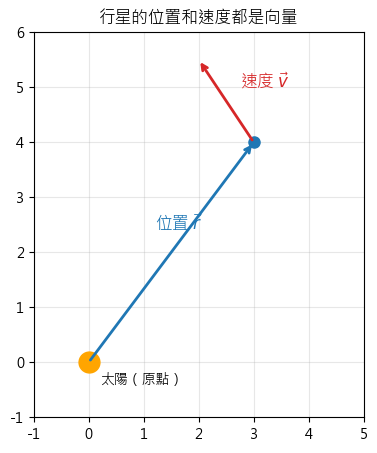

In [2]:
r = np.array([3.0, 4.0])      # 位置：往右 3、往上 4
v = np.array([-1.0, 1.5])     # 速度

print("位置向量 r =", r)
print("距離 |r| =", np.hypot(*r), "（畢氏定理：√(3² + 4²) = 5）")
print("r 的兩倍 =", 2 * r, "（方向不變，長度變兩倍）")
print("r + v =", r + v, "（箭頭頭尾相接）")
print("單位向量 r/|r| =", r / np.hypot(*r), "（同方向、長度 1，只保留「方向」）")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(0, 0, "o", color="orange", ms=15)
ax.text(0.2, -0.4, "太陽（原點）")
ax.annotate("", xy=r, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2, color="C0"))
ax.text(1.2, 2.4, r"位置 $\vec r$", color="C0", fontsize=12)
ax.annotate("", xy=r + v, xytext=r, arrowprops=dict(arrowstyle="->", lw=2, color="C3"))
ax.text(2.75, 5.0,r"速度 $\vec v$", color="C3", fontsize=12)
ax.plot(*r, "o", color="C0", ms=8)
ax.set_xlim(-1, 5)
ax.set_ylim(-1, 6)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.set_title("行星的位置和速度都是向量")
plt.show()

**單位向量**很重要：$\vec r / r$ 是一支長度為 1、方向和 $\vec r$ 相同的箭頭。
當我們想說「力的方向朝著太陽」，就會用到它。

**01 哪裡會用到**：程式裡所有的 `r`、`v` 都是這種兩個數字的陣列；`np.hypot(*r)` 就是在算距離 $r$。

## 2. 速度和加速度：變化率

**白話**：

- **速度** = 位置變化得多快 = $\dfrac{\text{位置的變化}}{\text{花了多少時間}} = \dfrac{\Delta x}{\Delta t}$
- **加速度** = 速度變化得多快 = $\dfrac{\Delta v}{\Delta t}$

高中算的是一段時間的**平均**速度。物理上要的是**某一瞬間**的速度，做法是把 $\Delta t$ 取得**非常非常小**。
這就是微積分裡「微分」的意思，符號寫成 $\dfrac{dx}{dt}$，或在上面加一點寫成 $\dot x$。

**親手看**：自由落體掉了 $x = \frac12 g t^2$（高中公式），$g = 9.8$。$t = 2$ 秒時的瞬間速度是多少？

In [3]:
g = 9.8
x = lambda t: 0.5 * g * t**2       # 自由落體的位置

t = 2.0
print(f"{'Δt':>10}{'平均速度 Δx/Δt':>20}")
for dt in [1, 0.1, 0.01, 0.001, 0.0001]:
    print(f"{dt:>10}{(x(t + dt) - x(t)) / dt:>20.5f}")
print(f"\n高中公式 v = g t = {g * t}")

        Δt          平均速度 Δx/Δt
         1            24.50000
       0.1            20.09000
      0.01            19.64900
     0.001            19.60490
    0.0001            19.60049

高中公式 v = g t = 19.6


**觀察**：$\Delta t$ 越小，平均速度越接近 19.6，也就是高中公式 $v = gt$ 給的答案。
**「瞬間速度」就是 $\Delta t$ 趨近於 0 時，平均速度逼近的那個值。**

所以 01 裡這條式子

$$\ddot{\vec r} = -\frac{GM}{r^3}\vec r$$

左邊的 $\ddot{\vec r}$（兩點）就是**加速度**。整句的意思是：「行星的加速度等於右邊那一串」。

## 3. 一小步一小步：電腦怎麼算運動

這一章是整本最重要的觀念。

**牛頓第二定律** $F = ma$ 告訴我們：知道受多大的力，就知道加速度。
可是我們想要的是**位置隨時間怎麼變**。電腦的做法很樸素：

1. 把時間切成很多小段，每段 $dt$
2. 每一小段裡，假裝速度和加速度都不變：
   - 新位置 = 舊位置 + 速度 × $dt$
   - 新速度 = 舊速度 + 加速度 × $dt$
3. 重複幾千幾萬次

這個方法叫 **Euler 法**，就是 01 實驗 1 裡的第一種積分器。

**親手看**：用 Euler 法算一顆往右上方丟出的球，再和高中的拋體公式比對：

dt = 0.4   2 秒後高度：+4.320 公尺（精確值 +0.400），誤差 +3.920
dt = 0.1   2 秒後高度：+1.380 公尺（精確值 +0.400），誤差 +0.980
dt = 0.01  2 秒後高度：+0.498 公尺（精確值 +0.400），誤差 +0.098


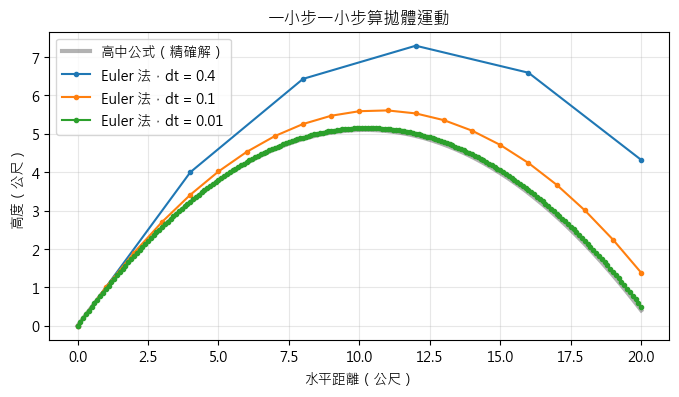

In [4]:
def throw_euler(dt, t_end=2.0):
    r = np.array([0.0, 0.0])        # 起點
    v = np.array([10.0, 10.0])      # 初速：往右 10、往上 10（公尺/秒）
    a = np.array([0.0, -9.8])       # 加速度：重力往下
    path = [r]
    for _ in range(int(round(t_end / dt))):
        r, v = r + v * dt, v + a * dt   # Euler 法的一步
        path.append(r)
    return np.array(path)

t = np.linspace(0, 2, 200)
exact_x, exact_y = 10 * t, 10 * t - 0.5 * 9.8 * t**2    # 高中公式

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(exact_x, exact_y, "k-", lw=3, alpha=0.3, label="高中公式（精確解）")
for dt in [0.4, 0.1, 0.01]:
    p = throw_euler(dt)
    ax.plot(p[:, 0], p[:, 1], "o-", ms=3, label=f"Euler 法，dt = {dt}")
    print(f"dt = {dt:<5} 2 秒後高度：{p[-1, 1]:+.3f} 公尺（精確值 {exact_y[-1]:+.3f}），誤差 {p[-1, 1] - exact_y[-1]:+.3f}")
ax.set_xlabel("水平距離（公尺）")
ax.set_ylabel("高度（公尺）")
ax.set_title("一小步一小步算拋體運動")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**觀察**：

- $dt$ 越小，Euler 法越接近精確解。
- Euler 法的球**總是飛得比較高**。因為每一步都用「這一步開始時」的速度往前走，而那時候的速度還沒被重力減掉。
- **誤差隨 $dt$ 等比例縮小**：$dt$ 從 0.1 變成 0.01（小 10 倍），誤差也剛好小 10 倍。這叫「一階」方法，誤差 $\propto dt$。

**01 哪裡會用到**：實驗 1 的 `step_euler` 就是上面那一行 `r, v = r + v * dt, v + a * dt`。
Verlet 和 Yoshida 是更聰明的走法，同樣的 $dt$ 誤差小很多，但基本精神一樣：**一小步一小步往前推**。

## 4. 萬有引力和行星軌道

**高中公式**：兩個質量互相吸引，大小是

$$F = \frac{GMm}{r^2}$$

距離變兩倍，引力變成四分之一，所以叫「**平方反比**」。

**加速度**：由 $F = ma$，行星的加速度大小是 $a = F/m = GM/r^2$（行星自己的質量 $m$ 消掉了，所以所有東西掉落得一樣快）。

**方向**：朝向太陽，也就是和位置向量 $\vec r$ **相反**。把大小乘上「指向太陽的單位向量」$-\vec r/r$：

$$\vec a = \frac{GM}{r^2}\times\left(-\frac{\vec r}{r}\right) = -\frac{GM}{r^3}\,\vec r$$

這就是 01 開頭那條式子。分母的 $r^3$ 不是什麼新的物理，只是 $r^2$（平方反比）再乘上一個 $r$（做成單位向量）。

**為什麼 $GM = 4\pi^2$**：用 AU 當長度、年當時間。地球近似做圓周運動，引力提供向心力：

$$\frac{v^2}{r} = \frac{GM}{r^2},\qquad v = \frac{2\pi r}{T}
\quad\Rightarrow\quad GM = \frac{4\pi^2 r^3}{T^2} = \frac{4\pi^2 \times 1^3}{1^2} = 4\pi^2$$

**親手看**：用第 3 章的 Euler 法，加上萬有引力，模擬地球繞太陽：

dt = 0.02    1 年後離太陽 2.3192 AU（應該是 1）
dt = 0.005   1 年後離太陽 1.3698 AU（應該是 1）
dt = 0.0005  1 年後離太陽 1.0389 AU（應該是 1）


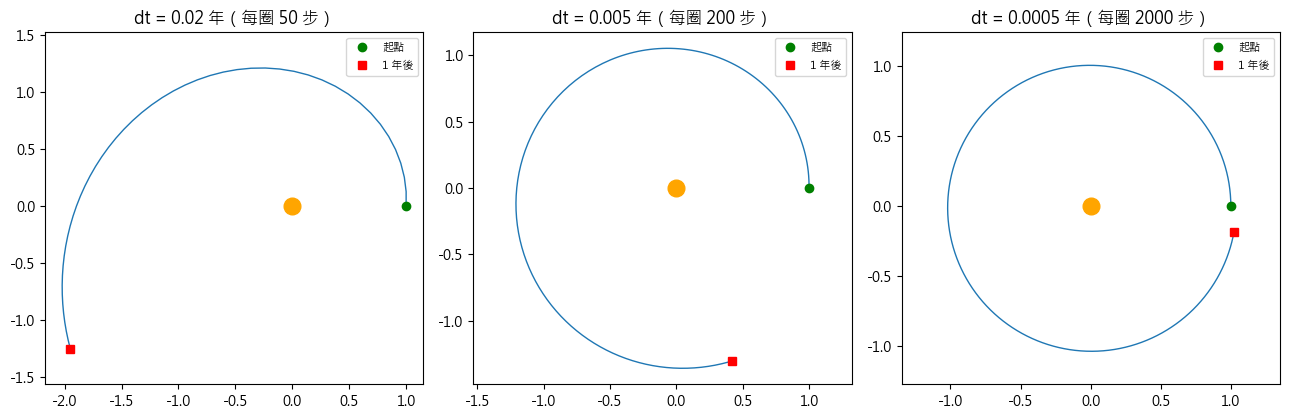

In [5]:
GM = 4 * np.pi**2                   # AU³/年²

def orbit_euler(dt, years=1.0):
    r = np.array([1.0, 0.0])                 # 地球在 1 AU
    v = np.array([0.0, 2 * np.pi])           # 圓周運動速度：周長 2π AU / 1 年
    path = [r]
    for _ in range(int(round(years / dt))):
        a = -GM * r / np.hypot(*r) ** 3      # 萬有引力的加速度
        r, v = r + v * dt, v + a * dt        # 和丟球一模一樣的 Euler 步驟
        path.append(r)
    return np.array(path)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, dt in zip(axes, [0.02, 0.005, 0.0005]):
    p = orbit_euler(dt)
    ax.plot(p[:, 0], p[:, 1], lw=1)
    ax.plot(0, 0, "o", color="orange", ms=12)
    ax.plot(*p[0], "go", label="起點")
    ax.plot(*p[-1], "rs", label="1 年後")
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(f"dt = {dt} 年（每圈 {int(1 / dt)} 步）")
    ax.legend(loc="best", fontsize=8)
    print(f"dt = {dt:<7} 1 年後離太陽 {np.hypot(*p[-1]):.4f} AU（應該是 1）")
plt.tight_layout()
plt.show()

**觀察**：

- 只用了**一條加速度公式和一行 Euler 步驟**，地球就自己繞出一圈軌道。這就是牛頓力學的威力：給定起點、速度和力，未來全部都算得出來（**決定論**）。
- $dt$ 太大時，地球會**螺旋往外飛**，1 年後回不到起點。這不是物理，是 Euler 法的誤差。
- $dt$ 越小越好，但要算的步數也越多。

**01 哪裡會用到**：01 的 `kepler_acc` 就是上面那行 `a = -GM * r / np.hypot(*r) ** 3`。
實驗 1 的 Euler 螺旋就是這張圖的現象。

## 5. 能量守恆：抓出模擬誤差

**白話**：行星的能量有兩種：

- **動能** $\frac12 mv^2$：跑得越快越多
- **重力位能** $-\dfrac{GMm}{r}$：離太陽越近越**低**

位能為什麼是負的？因為我們把「離太陽無限遠」定為 0。行星被太陽抓住，要**給它能量**才能逃到無限遠，所以它現在的能量比 0 還低。總能量是負的，就代表「被綁住了」，這叫束縛軌道。

**守恆**：沒有外力做功時，總能量 $E = \frac12 mv^2 - \frac{GMm}{r}$ **永遠不變**。
行星靠近太陽時，位能變低、動能變高（跑得快）；離遠時反過來，但總和不變。

**重點**：既然真正的物理能量不變，那麼**模擬裡能量變了多少，就代表模擬誤差有多大**。這是檢查程式最好用的工具。
（01 裡把行星質量 $m$ 都約掉，算的是每單位質量的能量 $E/m$，道理一樣。）

In [6]:
def energy(r, v):
    return 0.5 * v @ v - GM / np.hypot(*r)      # 每單位質量的能量

print(f"{'dt（年）':>10}{'起始能量':>12}{'1 年後能量':>12}{'能量變化':>12}")
for dt in [0.02, 0.005, 0.0005]:
    p = orbit_euler(dt)
    r_start, r_end = p[0], p[-1]
    v_start = np.array([0.0, 2 * np.pi])
    v_end = (p[-1] - p[-2]) / dt                  # 用最後一步估速度
    E0, E1 = energy(r_start, v_start), energy(r_end, v_end)
    print(f"{dt:>10}{E0:>12.3f}{E1:>12.3f}{(E1 - E0) / abs(E0):>+12.1%}")

     dt（年）        起始能量      1 年後能量        能量變化
      0.02     -19.739      -9.430      +52.2%
     0.005     -19.739     -15.185      +23.1%
    0.0005     -19.739     -19.017       +3.7%


**觀察**：Euler 法的能量一路**增加**，所以行星螺旋往外飛（能量越高，軌道越大）。$dt$ 越小，能量漂移越少。

**01 哪裡會用到**：實驗 1 右邊那張「能量相對誤差 |ΔE/E|」圖，就是用這個方法比較三種積分器誰比較準。
那張圖的縱軸是**對數刻度**：每一格差 100 倍。`1e-4` 是 0.0001，`1e-16` 是小數點後 15 個 0 再一個 1。

## 6. 橢圓和克卜勒三定律

行星軌道不是正圓，而是**橢圓**，太陽在橢圓的一個**焦點**上，不在正中間。描述橢圓只要兩個數字：

- **半長軸 $a$**：橢圓最長方向的一半，大致代表「軌道有多大」
- **偏心率 $e$**：有多扁。$e = 0$ 是正圓；水星 $e = 0.206$，是八大行星中最扁的；地球只有 0.017，幾乎是圓的

最靠近太陽的點叫**近日點**，距離 $a(1-e)$；最遠的點叫**遠日點**，距離 $a(1+e)$。

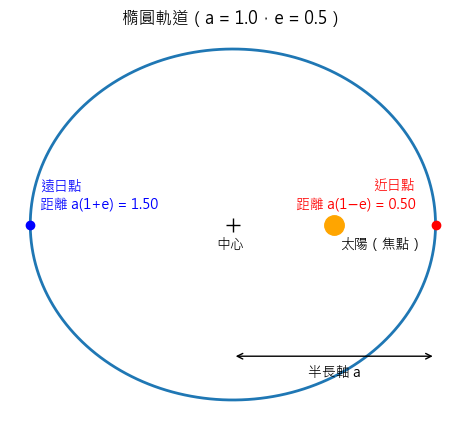

In [7]:
a, e = 1.0, 0.5           # 誇張一點的橢圓，比較好看
b = a * np.sqrt(1 - e**2) # 半短軸
c = a * e                 # 中心到焦點的距離
th = np.linspace(0, 2 * np.pi, 400)
X, Y = a * np.cos(th) - c, b * np.sin(th)   # 讓太陽（焦點）落在原點

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(X, Y, lw=2)
ax.plot(0, 0, "o", color="orange", ms=14)
ax.text(0.03, -0.12, "太陽（焦點）")
ax.plot(-c, 0, "k+", ms=10)
ax.text(-c - 0.08, -0.12, "中心")
ax.plot(a - c, 0, "ro")
ax.text(a - c - 0.1, 0.08, f"近日點\n距離 a(1−e) = {a * (1 - e):.2f}", color="r", ha="right")
ax.plot(-a - c, 0, "bo")
ax.text(-a - c + 0.05, 0.08, f"遠日點\n距離 a(1+e) = {a * (1 + e):.2f}", color="b")
ax.annotate("", xy=(a - c, -0.65), xytext=(-c, -0.65), arrowprops=dict(arrowstyle="<->"))
ax.text(a / 2 - c, -0.75, "半長軸 a", ha="center")
ax.set_aspect("equal")
ax.set_ylim(-0.95, 0.95)
ax.axis("off")
ax.set_title(f"橢圓軌道（a = {a}，e = {e}）")
plt.show()

**克卜勒三定律**（1609–1619 年，從觀測數據歸納出來的，比牛頓早）：

1. **橢圓定律**：行星軌道是橢圓，太陽在一個焦點上。
2. **等面積定律**：行星和太陽的連線，在相同時間內掃過相同面積。所以行星在近日點跑得快、遠日點跑得慢。
3. **週期定律**：$T^2 \propto a^3$。用 AU 和年當單位，就是 $T^2 = a^3$。例如火星 $a = 1.524$，$T = 1.524^{1.5} = 1.88$ 年。

牛頓的偉大之處，是證明了這三條定律全都可以從「平方反比的萬有引力」推導出來。

**01 哪裡會用到**：實驗 2 驗證第 3 條；程式裡的 `aM, eM` 就是水星的 $a$ 和 $e$；
`start_at_perihelion` 把行星放在近日點出發，速度用一個叫「活力公式」的式子算，**把它當成給定的工具就好**。

## 7. 進動：會轉的橢圓

**白話**：如果太陽系裡只有太陽和一顆行星，引力又剛好是平方反比，行星會**永遠沿著同一個橢圓跑**，近日點永遠在同一個方向（第 4 章的模擬就是這樣）。

但如果有別的力介入，例如其他行星的拉扯，或者引力不是剛好平方反比，橢圓就會**一圈一圈慢慢轉**，近日點的方向會跟著移動。這叫**近日點進動**。

下面這張圖把進動誇張化：每一圈轉 15°。真實的水星每一圈只轉大約 0.0004°。

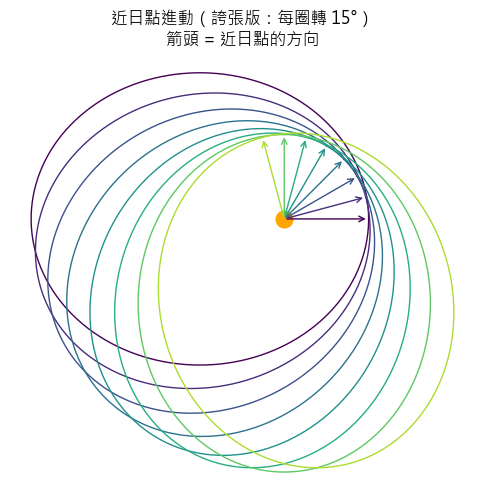

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
a, e = 1.0, 0.5
b, c = a * np.sqrt(1 - e**2), a * e
th = np.linspace(0, 2 * np.pi, 300)
for i in range(8):
    phi = np.radians(15 * i)                     # 第 i 圈，整個橢圓轉了 15°×i
    X, Y = a * np.cos(th) - c, b * np.sin(th)
    Xr, Yr = X * np.cos(phi) - Y * np.sin(phi), X * np.sin(phi) + Y * np.cos(phi)
    ax.plot(Xr, Yr, lw=1, color=plt.cm.viridis(i / 8))
    px, py = (a - c) * np.cos(phi), (a - c) * np.sin(phi)
    ax.annotate("", xy=(px, py), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=plt.cm.viridis(i / 8)))
ax.plot(0, 0, "o", color="orange", ms=12)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("近日點進動（誇張版：每圈轉 15°）\n箭頭 = 近日點的方向")
plt.show()

**怎麼量近日點的方向？** 01 用了一個叫 **Runge–Lenz 向量**的東西。名字很嚇人，但你只要知道：

> 它是一支用位置和速度算出來的箭頭，**永遠指向近日點**，就像上圖的箭頭。

在純平方反比的世界裡，這支箭頭**永遠不動**。所以只要追蹤它轉了多少，就知道進動了多少。

**01 哪裡會用到**：實驗 3 確認只有太陽時箭頭不動；實驗 4 加入其他行星，量箭頭轉得多快。

## 8. 角秒：43″ 到底有多小

**角度單位**：

| 單位 | 換算 |
|---|---|
| 1 圈 | 360° |
| 1 度 (°) | 60 角分 (′) |
| 1 角分 (′) | 60 角秒 (″) |
| 所以 1° | = 3600″ |
| **弧度 (rad)** | 數學和程式用的角度單位：1 圈 = $2\pi$ 弧度，1 弧度 ≈ 57.3° |

numpy 的 `np.sin`、`np.arctan2` 都用**弧度**。01 裡的 `ARCSEC = 180 / np.pi * 3600` 就是「弧度 → 角秒」的換算係數。

**43″／世紀有多小？** 算算看：

In [9]:
arcsec = 43
rad = arcsec / 3600 * np.pi / 180          # 角秒 → 弧度
coin = 0.020                                # 一元硬幣直徑 20 mm
print(f"43 角秒 = {arcsec / 3600:.5f} 度 = {rad:.2e} 弧度")
print(f"相當於從 {coin / rad:.0f} 公尺外看一枚一元硬幣的角度")
print(f"水星近日點要多轉滿一整圈：360° × 3600 / 43 × 100 年 = {360 * 3600 / 43 * 100 / 1e6:.1f} 百萬年")

43 角秒 = 0.01194 度 = 2.08e-04 弧度
相當於從 96 公尺外看一枚一元硬幣的角度
水星近日點要多轉滿一整圈：360° × 3600 / 43 × 100 年 = 3.0 百萬年


**意義**：每一百年才多轉「從快 100 公尺外看一枚硬幣」那麼小的角度。19 世紀的天文學家能量出這麼小的偏差，並且確定牛頓力學解釋不了，是觀測史上非常了不起的成就。
這也是為什麼 01 必須先確認**數值誤差遠小於 43″**，否則量到的可能只是程式的錯。

## 9. 誤差「正比於 $dt^2$」是什麼意思

01 實驗 3 有一張表，說 Verlet 的誤差 $\propto dt^2$、Yoshida 的誤差 $\propto dt^4$。意思是：

| 誤差正比於 | $dt$ 縮小一半，誤差變成 | $dt$ 縮小 10 倍，誤差變成 | 例子 |
|---|---|---|---|
| $dt$ | 1/2 | 1/10 | Euler（第 3 章的丟球） |
| $dt^2$ | 1/4 | 1/100 | Verlet |
| $dt^4$ | 1/16 | 1/10000 | Yoshida |

**次方越高，縮小步長的回報就越大。** 這也是為什麼要用 Yoshida 而不用 Euler：
想達到同樣的精確度，Euler 可能要跑好幾億步，Yoshida 幾十萬步就夠了。

**親手看**：用第 3 章的丟球驗證 Euler 是「一階」的：

In [10]:
exact = 10 * 2 - 0.5 * 9.8 * 2**2
prev = None
print(f"{'dt':>8}{'誤差':>12}{'和上一行的比值':>16}")
for dt in [0.2, 0.1, 0.05, 0.025]:
    err = throw_euler(dt)[-1, 1] - exact
    ratio = "" if prev is None else f"{prev / err:.2f}"
    print(f"{dt:>8}{err:>12.4f}{ratio:>16}")
    prev = err

      dt          誤差         和上一行的比值
     0.2      1.9600                
     0.1      0.9800            2.00
    0.05      0.4900            2.00
   0.025      0.2450            2.00


**觀察**：每次 $dt$ 減半，誤差剛好減半（比值 2.00），證實 Euler 的誤差 $\propto dt$。
01 實驗 3 用同樣的方法，量出 Verlet 的比值約 4、Yoshida 的比值約 16。

## 準備好了：回去讀 01

| 你在 01 看到 | 這本的哪裡 |
|---|---|
| $\ddot{\vec r} = -\dfrac{GM}{r^3}\vec r$ | 第 2 章（兩點 = 加速度）、第 4 章（$r^3$ 從哪來） |
| $GM = 4\pi^2$、AU、年 | 第 4 章 |
| Euler、Verlet、Yoshida、`step_...` | 第 3 章、第 9 章 |
| 能量相對誤差 \|ΔE/E\| | 第 5 章 |
| $a$、$e$、近日點、`start_at_perihelion` | 第 6 章 |
| 克卜勒第三定律 $T^2 \propto a^3$ | 第 6 章 |
| Runge–Lenz 向量、進動 | 第 7 章 |
| 角秒 ″、`ARCSEC` | 第 8 章 |
| 誤差 $\propto dt^2$、$dt^4$ | 第 9 章 |

01 實驗 4 裡的「Laplace–Lagrange 攝動理論」和「間接項」是比較進階的天體力學，**看不懂沒關係**。
只要知道：「有一個解析公式可以獨立算出其他行星造成的進動，用來檢查模擬對不對」。

## 小練習

1. 第 3 章把初速改成 `[10.0, 20.0]`，球會飛多高？和高中公式 $h = v_y^2 / 2g$ 比對。
2. 第 4 章把地球的初速從 `2 * np.pi` 改成 `1.2 * 2 * np.pi`（快 20%），軌道變成什麼形狀？再改成 `1.5 * 2 * np.pi` 呢？
   （提示：速度超過 $\sqrt2$ 倍，總能量會變成正的，行星就會逃走。）
3. 用克卜勒第三定律算：木星 $a = 5.2$ AU，繞太陽一圈要幾年？